# 10 – Model Comparison and Selection

This notebook compares the forecasting performance of the models developed in Notebooks 05–08 using the 2025 validation dataset.

The objective is to identify the best-performing model for the final out-of-sample evaluation in 2026. Model performance is assessed using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), with particular attention to differences between model specifications and training-window approaches.

Model selection is based exclusively on the 2025 validation results. The 2026 test dataset remains unseen during this process to ensure an unbiased final evaluation.

## 1. Load Validation Predictions

The validation predictions generated in Notebooks 05–08 are loaded from five CSV files, covering the Lag-7 baseline, linear regression models, Random Forest models, and different training-window approaches.

Each file contains daily predictions and actual electricity consumption values for the 2025 validation period. These results provide the basis for comparing forecasting accuracy and selecting the best-performing model.



In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Define project directory
ROOT = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()

# Paths to validation predictions
TABLES = ROOT / "output" / "tables"

# Load prediction files
baseline = pd.read_csv(TABLES / "baseline_validation_predictions.csv")
linear = pd.read_csv(TABLES / "linear_models_validation_predictions.csv")
rf = pd.read_csv(TABLES / "random_forest_validation.csv")
rf_tuned = pd.read_csv(TABLES / "random_forest_tuned_validation.csv")
windows = pd.read_csv(TABLES / "training_windows_validation.csv")

print("All validation prediction files loaded successfully.")
print("Baseline:", len(baseline))
print("Linear models:", len(linear))
print("Random Forest:", len(rf))
print("Tuned Random Forest:", len(rf_tuned))
print("Training windows:", len(windows))


All validation prediction files loaded successfully.
Baseline: 365
Linear models: 2190
Random Forest: 365
Tuned Random Forest: 365
Training windows: 1460



## 2. Combine Model Predictions

The validation predictions from the five source files are combined into a single dataset to enable a consistent comparison across all model variants.

For each model, the Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) are calculated. The models are then ranked by their MAE, with lower values indicating higher forecasting accuracy.


In [3]:

# Combine all validation predictions
datasets = {
    "baseline": baseline,
    "linear": linear,
    "random_forest": rf,
    "random_forest_tuned": rf_tuned,
    "training_windows": windows
}

all_predictions = pd.concat(
    [
        data.assign(source=source)
        for source, data in datasets.items()
    ],
    ignore_index=True
)

# Calculate evaluation metrics for each model
results = []

for (source, model), group in all_predictions.groupby(
    ["source", "model"]
):
    errors = (
        group["actual_mwh"] - group["predicted_mwh"]
    )

    results.append({
        "source": source,
        "model": model,
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2))
    })

# Create and sort comparison table
comparison = pd.DataFrame(results)
comparison = comparison.sort_values("MAE").reset_index(drop=True)

display(comparison.round(2))


,source,model,MAE,RMSE
0,training_windows,ols_rolling_3y,74.64,97.66
1,training_windows,ols_expanding,80.36,105.44
2,linear,ols_with_weather,80.36,105.44
3,training_windows,random_forest_rolling_3y,81.66,104.18
4,linear,ridge_with_weather,81.79,107.45
5,linear,lasso_with_weather,83.57,109.15
6,random_forest,random_forest_expanding,86.79,115.27
7,training_windows,random_forest_expanding,86.79,115.27
8,random_forest_tuned,random_forest_tuned_expanding,87.24,115.99
9,linear,ols_no_weather,99.55,130.96



## 3. Initial Model Performance Comparison

The forecasting accuracy of all model variants is visualized using their Mean Absolute Error (MAE) on the 2025 validation dataset.

The bar chart provides an initial overview of the differences in predictive performance and helps identify the most promising models for further comparison.


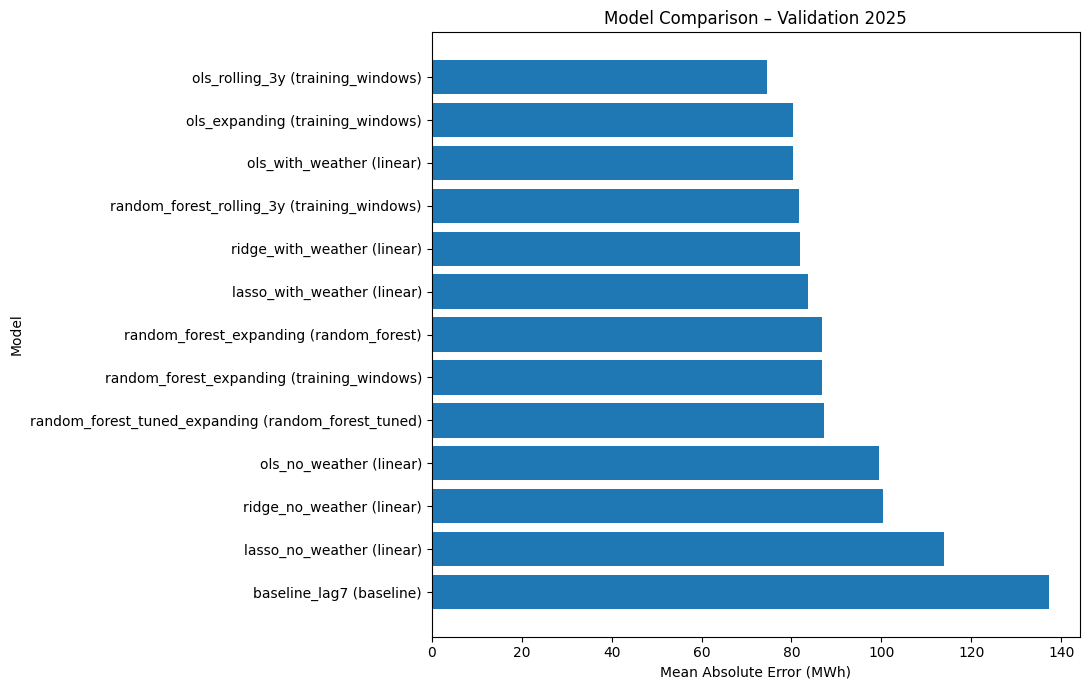

In [4]:

# Visual comparison of model performance

plot_data = comparison.copy()

# Create labels including the source
plot_data["label"] = (
    plot_data["model"] + " (" + plot_data["source"] + ")"
)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["label"],
    plot_data["MAE"]
)

plt.xlabel("Mean Absolute Error (MWh)")
plt.ylabel("Model")
plt.title("Model Comparison – Validation 2025")

# Best-performing model at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()



## 4. Verification of Duplicate Model Predictions

Some model variants appear in multiple prediction files because they were evaluated in different notebooks.

To avoid counting identical models more than once, their daily predictions are compared directly. This verifies whether the corresponding model variants produce identical forecasts for the same validation dates.


In [5]:

# Check whether repeated model results have identical predictions

def compare_predictions(first, second):
    a = first[["date", "predicted_mwh"]].copy()
    b = second[["date", "predicted_mwh"]].copy()

    merged = a.merge(
        b,
        on="date",
        suffixes=("_first", "_second"),
        validate="one_to_one"
    )

    same_coverage = (
        len(merged) == len(a) == len(b)
    )

    same_predictions = np.allclose(
        merged["predicted_mwh_first"],
        merged["predicted_mwh_second"],
        rtol=0,
        atol=1e-6
    )

    return same_coverage and same_predictions


# Compare OLS variants
ols_same = compare_predictions(
    linear[linear["model"] == "ols_with_weather"],
    windows[windows["model"] == "ols_expanding"]
)

# Compare Random Forest variants
rf_same = compare_predictions(
    rf[rf["model"] == "random_forest_expanding"],
    windows[windows["model"] == "random_forest_expanding"]
)

print("OLS predictions identical:", ols_same)
print("Random Forest predictions identical:", rf_same)


OLS predictions identical: True
Random Forest predictions identical: True



## 5. Remove Duplicate Model Variants

The comparison of daily predictions confirms that two model variants are represented in multiple source files.

These duplicate entries are removed to ensure that each distinct forecasting model is included only once in the final performance comparison.

The resulting dataset contains 11 unique model variants, ranked by their validation MAE.


In [6]:

# Remove confirmed duplicate model variants

clean_comparison = comparison[
    ~(
        ((comparison["source"] == "training_windows") &
         (comparison["model"] == "ols_expanding"))
        |
        ((comparison["source"] == "training_windows") &
         (comparison["model"] == "random_forest_expanding"))
    )
].copy()

# Sort by MAE and reset index
clean_comparison = (
    clean_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("Number of unique model variants:", len(clean_comparison))

display(clean_comparison.round(2))


Number of unique model variants: 11


,source,model,MAE,RMSE
0,training_windows,ols_rolling_3y,74.64,97.66
1,linear,ols_with_weather,80.36,105.44
2,training_windows,random_forest_rolling_3y,81.66,104.18
3,linear,ridge_with_weather,81.79,107.45
4,linear,lasso_with_weather,83.57,109.15
5,random_forest,random_forest_expanding,86.79,115.27
6,random_forest_tuned,random_forest_tuned_expanding,87.24,115.99
7,linear,ols_no_weather,99.55,130.96
8,linear,ridge_no_weather,100.27,131.54
9,linear,lasso_no_weather,113.99,148.90



## 6. Performance Improvement Relative to Baseline

The performance of each model is compared with the Lag-7 baseline, which predicts electricity consumption using the value observed on the same weekday of the previous week.

The percentage improvements in MAE and RMSE quantify how much each model reduces forecasting errors relative to this simple benchmark.

Positive values indicate an improvement over the baseline, while negative values indicate worse predictive performance.


In [7]:

# Calculate improvement relative to the baseline

baseline_mae = clean_comparison.loc[
    clean_comparison["model"] == "baseline_lag7",
    "MAE"
].iloc[0]

baseline_rmse = clean_comparison.loc[
    clean_comparison["model"] == "baseline_lag7",
    "RMSE"
].iloc[0]

clean_comparison["MAE_improvement_%"] = (
    (baseline_mae - clean_comparison["MAE"])
    / baseline_mae * 100
)

clean_comparison["RMSE_improvement_%"] = (
    (baseline_rmse - clean_comparison["RMSE"])
    / baseline_rmse * 100
)

display(clean_comparison.round(2))


,source,model,MAE,RMSE,MAE_improvement_%,RMSE_improvement_%
0,training_windows,ols_rolling_3y,74.64,97.66,45.62,51.54
1,linear,ols_with_weather,80.36,105.44,41.46,47.68
2,training_windows,random_forest_rolling_3y,81.66,104.18,40.52,48.31
3,linear,ridge_with_weather,81.79,107.45,40.42,46.69
4,linear,lasso_with_weather,83.57,109.15,39.12,45.84
5,random_forest,random_forest_expanding,86.79,115.27,36.78,42.81
6,random_forest_tuned,random_forest_tuned_expanding,87.24,115.99,36.45,42.45
7,linear,ols_no_weather,99.55,130.96,27.48,35.02
8,linear,ridge_no_weather,100.27,131.54,26.96,34.73
9,linear,lasso_no_weather,113.99,148.90,16.96,26.12



## 7. Final Model Performance Comparison

The final comparison includes all 11 distinct forecasting model variants evaluated on the 2025 validation dataset.

The models are ranked by their Mean Absolute Error (MAE), providing a direct comparison of their forecasting accuracy. The best-performing model is highlighted in green.

This comparison forms the basis for selecting the model used in the final out-of-sample evaluation.


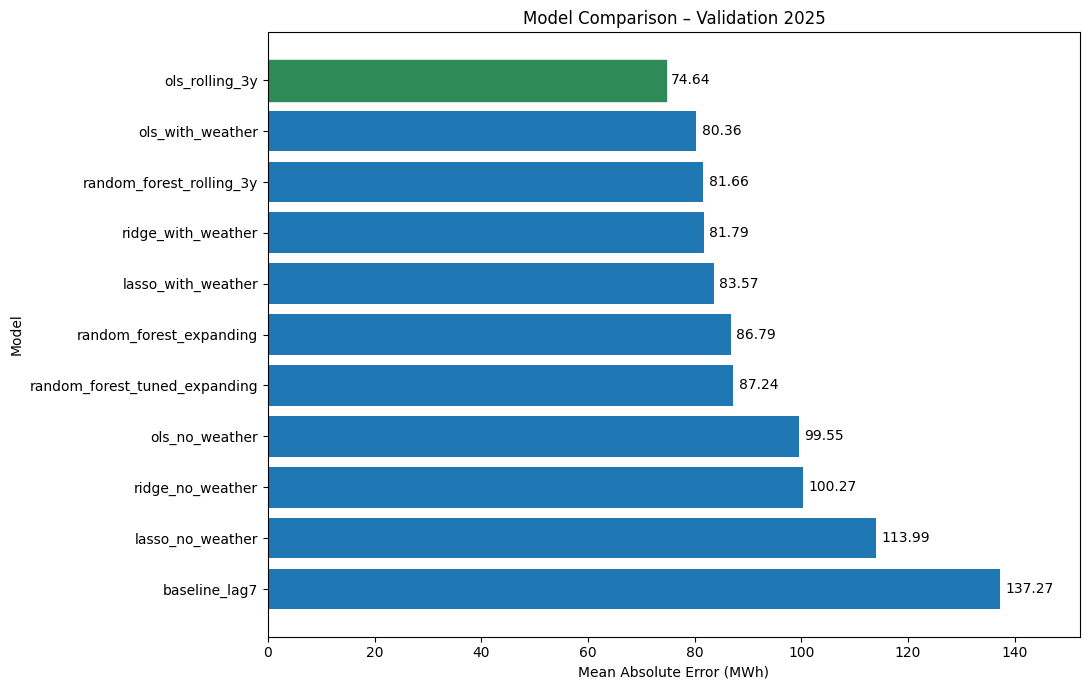

In [8]:

# Final model comparison chart (without duplicates)

plot_data = clean_comparison.copy()

plt.figure(figsize=(11, 7))

bars = plt.barh(
    plot_data["model"],
    plot_data["MAE"]
)

# Highlight the best-performing model
bars[0].set_color("seagreen")

# Display MAE values next to the bars
for bar, mae in zip(bars, plot_data["MAE"]):
    plt.text(
        mae + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{mae:.2f}",
        va="center"
    )

plt.xlabel("Mean Absolute Error (MWh)")
plt.ylabel("Model")
plt.title("Model Comparison – Validation 2025")

plt.gca().invert_yaxis()
plt.xlim(0, plot_data["MAE"].max() + 15)

plt.tight_layout()
plt.show()



## 8. Monthly Forecast Error Analysis

The forecasting performance of the Lag-7 baseline and the two OLS models is examined separately for each month of the 2025 validation period.

Monthly MAE values provide additional insights into the consistency of model performance throughout the year and reveal potential seasonal differences in forecasting accuracy.

This analysis also allows a more detailed comparison between the expanding and three-year rolling training windows.


In [9]:

# Monthly MAE comparison for selected models

selected_predictions = pd.concat(
    [
        baseline[baseline["model"] == "baseline_lag7"],
        linear[linear["model"] == "ols_with_weather"],
        windows[windows["model"] == "ols_rolling_3y"]
    ],
    ignore_index=True
)

# Convert dates and identify months
selected_predictions["date"] = pd.to_datetime(
    selected_predictions["date"]
)

selected_predictions["month"] = (
    selected_predictions["date"].dt.month
)

# Calculate absolute prediction errors
selected_predictions["absolute_error"] = (
    selected_predictions["actual_mwh"]
    - selected_predictions["predicted_mwh"]
).abs()

# Calculate monthly MAE
monthly_mae = (
    selected_predictions
    .groupby(["month", "model"])["absolute_error"]
    .mean()
    .unstack()
)

display(monthly_mae.round(2))


model,baseline_lag7,ols_rolling_3y,ols_with_weather
month,,,
1,163.27,91.22,119.63
2,88.99,76.49,45.90
3,126.53,67.48,88.96
4,116.45,62.16,66.27
5,147.09,75.46,83.25
6,193.09,76.39,85.33
7,195.13,105.42,138.37
8,240.51,116.81,87.68
9,92.39,46.19,58.10



## 9. Monthly Forecast Error Visualization

The monthly Mean Absolute Error (MAE) of the Lag-7 baseline and the two OLS models is visualized across the 2025 validation period.

The line chart illustrates how forecasting accuracy varies throughout the year and highlights differences between the expanding and rolling training windows.

Lower MAE values indicate better predictive performance.


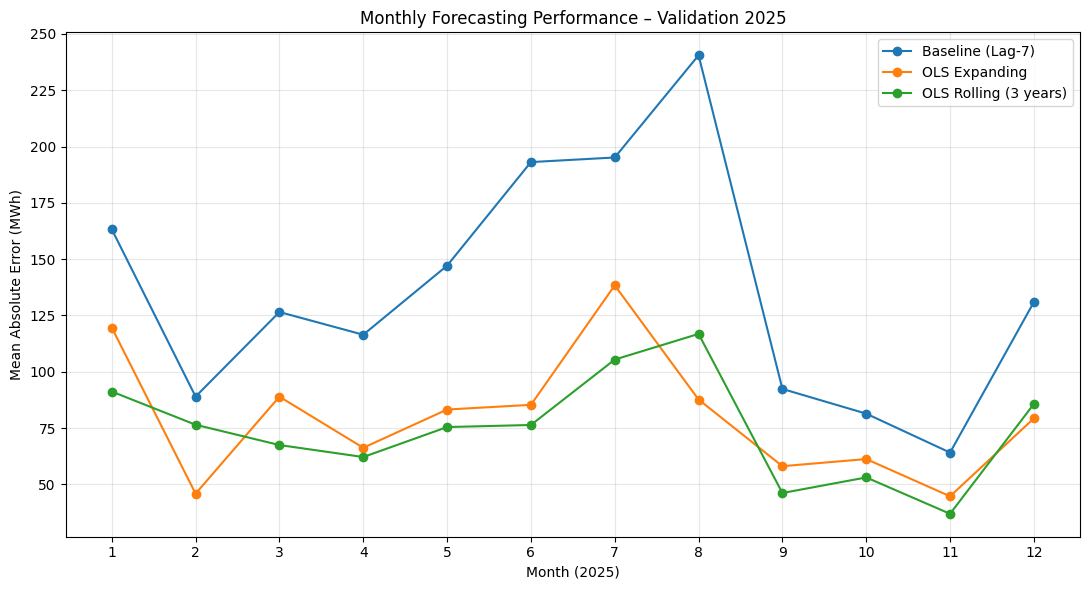

In [10]:

# Visualize monthly forecasting errors

plt.figure(figsize=(11, 6))

plt.plot(
    monthly_mae.index,
    monthly_mae["baseline_lag7"],
    marker="o",
    label="Baseline (Lag-7)"
)

plt.plot(
    monthly_mae.index,
    monthly_mae["ols_with_weather"],
    marker="o",
    label="OLS Expanding"
)

plt.plot(
    monthly_mae.index,
    monthly_mae["ols_rolling_3y"],
    marker="o",
    label="OLS Rolling (3 years)"
)

plt.xlabel("Month (2025)")
plt.ylabel("Mean Absolute Error (MWh)")
plt.title("Monthly Forecasting Performance – Validation 2025")

plt.xticks(range(1, 13))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Final Model Selection

The comparison of 11 distinct forecasting model variants shows that **OLS with a three-year rolling training window** achieves the best overall predictive performance on the 2025 validation dataset.

The model obtains a **MAE of 74.64 MWh** and a **RMSE of 97.66 MWh**, representing improvements of 45.62% and 51.54%, respectively, compared with the Lag-7 baseline.

The monthly analysis indicates that the rolling-window model generally performs better than the expanding-window OLS model, although the latter achieves lower errors in certain months. This suggests that a shorter training window may be beneficial when consumption patterns change over time, but the results do not establish the underlying cause.

Based on the lowest validation MAE and RMSE, **OLS with a three-year rolling window is selected as the preferred model for final evaluation**.

The 2026 test dataset has not been used for model selection and will be evaluated separately to assess out-of-sample performance.